<a href="https://colab.research.google.com/github/HongYoonSung/2026LA_Practice/blob/main/Tiefighter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
%%writefile my_utils.py
import numpy as np

# 1. 이동 변환 (Translation)
def translate(p, dx, dy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

# 2. 크기 변환 (Scaling)
def scale(p, sx, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

# 3. 회전 변환 (Rotation)
def rotate(p, theta):
    c = np.cos(theta)
    s = np.sin(theta)
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[c, -s, 0.0], [s, c, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

# 4. x축 기울기 변환 (Shear X)
def shear_x(p, sx):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, sx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

# 5. y축 기울기 변환 (Shear Y)
def shear_y(p, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, 0.0, 0.0], [sy, 1.0, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

# 6. x축 반전 (Reflection X)
def reflect_x(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

# 7. y축 반전 (Reflection Y)
def reflect_y(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[-1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

# 8. 원점 반전 (Reflection Origin)
def reflect_origin(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

# 9. y=x 대칭 반전 (Reflection Y=X)
def reflect_yx(p):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([[0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

Overwriting my_utils.py


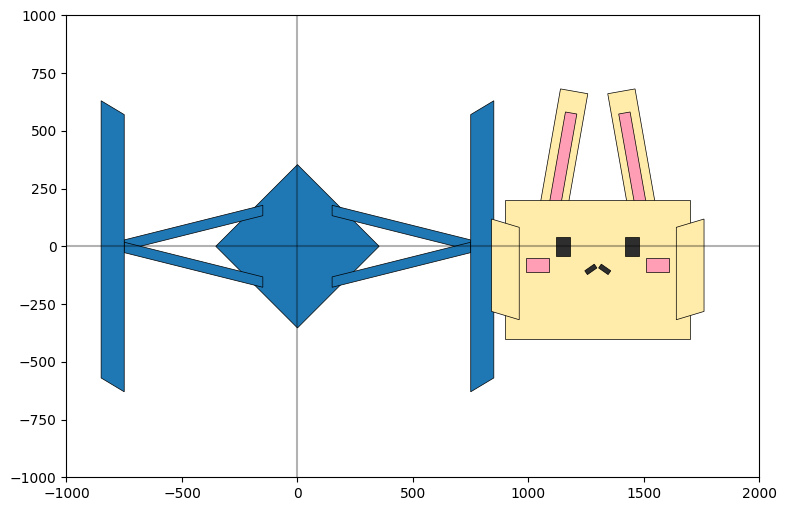

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

from my_utils import (
    translate, scale, rotate, shear_x, shear_y,
    reflect_x, reflect_y, reflect_origin, reflect_yx
)

INF = 1000  # 그림판 기본 범위
LEN = 100   # 사각형 기본 크기

def draw_axis(ax):
    ax.axhline(0, color='black', alpha=0.3)
    ax.axvline(0, color='black', alpha=0.3)
    ax.set_xlim(-1000, 2000)
    ax.set_ylim(-1000, 1000)
    ax.set_aspect('equal')

def draw_rectangle(ax, p1, p2, p3, p4, color='#1f77b4'):
    my_polygon = Polygon([p1, p2, p3, p4], facecolor=color, edgecolor='black', linewidth=0.5)
    ax.add_patch(my_polygon)


def draw_cockpit(ax, p1, p2, p3, p4):
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    s = 5
    q1 = scale(q1, s, s)
    q2 = scale(q2, s, s)
    q3 = scale(q3, s, s)
    q4 = scale(q4, s, s)

    q1 = rotate(q1, np.pi/4.0)
    q2 = rotate(q2, np.pi/4.0)
    q3 = rotate(q3, np.pi/4.0)
    q4 = rotate(q4, np.pi/4.0)

    draw_rectangle(ax, q1, q2, q3, q4)

def draw_left_arm(ax, p1, p2, p3, p4):
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    q1 = scale(q1, 6.0, 0.45)
    q2 = scale(q2, 6.0, 0.45)
    q3 = scale(q3, 6.0, 0.45)
    q4 = scale(q4, 6.0, 0.45)

    q1 = shear_y(q1, 0.25)
    q2 = shear_y(q2, 0.25)
    q3 = shear_y(q3, 0.25)
    q4 = shear_y(q4, 0.25)

    q1 = translate(q1, -450, 80)
    q2 = translate(q2, -450, 80)
    q3 = translate(q3, -450, 80)
    q4 = translate(q4, -450, 80)

    draw_rectangle(ax, q1, q2, q3, q4)

    rq1, rq2, rq3, rq4 = reflect_x(q1), reflect_x(q2), reflect_x(q3), reflect_x(q4)
    draw_rectangle(ax, rq1, rq2, rq3, rq4)

def draw_left_wing(ax, p1, p2, p3, p4):
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    q1 = scale(q1, 1.0, 12.0)
    q2 = scale(q2, 1.0, 12.0)
    q3 = scale(q3, 1.0, 12.0)
    q4 = scale(q4, 1.0, 12.0)

    q1 = shear_y(q1, -0.6)
    q2 = shear_y(q2, -0.6)
    q3 = shear_y(q3, -0.6)
    q4 = shear_y(q4, -0.6)

    q1 = translate(q1, -800, 0)
    q2 = translate(q2, -800, 0)
    q3 = translate(q3, -800, 0)
    q4 = translate(q4, -800, 0)

    draw_rectangle(ax, q1, q2, q3, q4)

def draw_right_arm(ax, p1, p2, p3, p4):
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    q1 = scale(q1, 6.0, 0.45)
    q2 = scale(q2, 6.0, 0.45)
    q3 = scale(q3, 6.0, 0.45)
    q4 = scale(q4, 6.0, 0.45)

    q1 = shear_y(q1, 0.25)
    q2 = shear_y(q2, 0.25)
    q3 = shear_y(q3, 0.25)
    q4 = shear_y(q4, 0.25)

    q1 = translate(q1, -450, 80)
    q2 = translate(q2, -450, 80)
    q3 = translate(q3, -450, 80)
    q4 = translate(q4, -450, 80)

    rq1_top, rq2_top, rq3_top, rq4_top = reflect_y(q1), reflect_y(q2), reflect_y(q3), reflect_y(q4)
    draw_rectangle(ax, rq1_top, rq2_top, rq3_top, rq4_top)

    rq1_bot, rq2_bot, rq3_bot, rq4_bot = reflect_x(q1), reflect_x(q2), reflect_x(q3), reflect_x(q4)
    rq1_bot, rq2_bot, rq3_bot, rq4_bot = reflect_y(rq1_bot), reflect_y(rq2_bot), reflect_y(rq3_bot), reflect_y(rq4_bot)
    draw_rectangle(ax, rq1_bot, rq2_bot, rq3_bot, rq4_bot)

def draw_right_wing(ax, p1, p2, p3, p4):
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    q1 = scale(q1, 1.0, 12.0)
    q2 = scale(q2, 1.0, 12.0)
    q3 = scale(q3, 1.0, 12.0)
    q4 = scale(q4, 1.0, 12.0)

    q1 = shear_y(q1, -0.6)
    q2 = shear_y(q2, -0.6)
    q3 = shear_y(q3, -0.6)
    q4 = shear_y(q4, -0.6)

    q1 = translate(q1, -800, 0)
    q2 = translate(q2, -800, 0)
    q3 = translate(q3, -800, 0)
    q4 = translate(q4, -800, 0)

    q1, q2, q3, q4 = reflect_y(q1), reflect_y(q2), reflect_y(q3), reflect_y(q4)
    draw_rectangle(ax, q1, q2, q3, q4)

def draw_tiefighter(ax, p1, p2, p3, p4):
    draw_cockpit(ax, p1, p2, p3, p4)
    draw_left_arm(ax, p1, p2, p3, p4)
    draw_left_wing(ax, p1, p2, p3, p4)
    draw_right_arm(ax, p1, p2, p3, p4)
    draw_right_wing(ax, p1, p2, p3, p4)


def draw_usagi_face(ax, p1, p2, p3, p4, offset_x):
    q = [translate(p, -LEN/2, -LEN/2) for p in [p1, p2, p3, p4]]


    face_center = [scale(p, 8.0, 6.0) for p in q]
    face_center = [translate(p, offset_x, -100) for p in face_center]
    draw_rectangle(ax, *face_center, color="#ffebaa")

    for side in [-1, 1]:
        cheek = [scale(p, 1.2, 4.0) for p in q]
        cheek = [shear_y(p, side * 0.3) for p in cheek]
        cheek = [translate(p, offset_x + side * 400, -100) for p in cheek]
        draw_rectangle(ax, *cheek, color="#ffebaa")

def draw_usagi_ears(ax, p1, p2, p3, p4, offset_x):
    q = [translate(p, -LEN/2, -LEN/2) for p in [p1, p2, p3, p4]]


    left_ear = [scale(p, 1.2, 5.5) for p in q]
    left_ear = [rotate(p, np.radians(-10)) for p in left_ear]
    left_ear = [translate(p, offset_x - 150, 400) for p in left_ear]
    draw_rectangle(ax, *left_ear, color="#ffebaa")

    left_inner = [scale(p, 0.5, 4.0) for p in q]
    left_inner = [rotate(p, np.radians(-10)) for p in left_inner]
    left_inner = [translate(p, offset_x - 150, 380) for p in left_inner]
    draw_rectangle(ax, *left_inner, color="#ff9eb5")


    right_ear = [scale(p, 1.2, 5.5) for p in q]
    right_ear = [rotate(p, np.radians(10)) for p in right_ear]
    right_ear = [translate(p, offset_x + 150, 400) for p in right_ear]
    draw_rectangle(ax, *right_ear, color="#ffebaa")

    right_inner = [scale(p, 0.5, 4.0) for p in q]
    right_inner = [rotate(p, np.radians(10)) for p in right_inner]
    right_inner = [translate(p, offset_x + 150, 380) for p in right_inner]
    draw_rectangle(ax, *right_inner, color="#ff9eb5")

def draw_usagi_face_features(ax, p1, p2, p3, p4, offset_x):
    q = [translate(p, -LEN/2, -LEN/2) for p in [p1, p2, p3, p4]]

    # 눈
    left_eye = [scale(p, 0.6, 0.8) for p in q]
    left_eye = [translate(p, offset_x - 150, 0) for p in left_eye]
    draw_rectangle(ax, *left_eye, color="#2e2e2e")

    right_eye = [scale(p, 0.6, 0.8) for p in q]
    right_eye = [translate(p, offset_x + 150, 0) for p in right_eye]
    draw_rectangle(ax, *right_eye, color="#2e2e2e")


    left_cheek = [scale(p, 1.0, 0.6) for p in q]
    left_cheek = [translate(p, offset_x - 260, -80) for p in left_cheek]
    draw_rectangle(ax, *left_cheek, color="#ff9eb5")

    right_cheek = [scale(p, 1.0, 0.6) for p in q]
    right_cheek = [translate(p, offset_x + 260, -80) for p in right_cheek]
    draw_rectangle(ax, *right_cheek, color="#ff9eb5")


    mouth_l = [scale(p, 0.5, 0.2) for p in q]
    mouth_l = [rotate(p, np.radians(35)) for p in mouth_l]
    mouth_l = [translate(p, offset_x - 30, -100) for p in mouth_l]
    draw_rectangle(ax, *mouth_l, color="#2e2e2e")

    mouth_r = [scale(p, 0.5, 0.2) for p in q]
    mouth_r = [rotate(p, np.radians(-35)) for p in mouth_r]
    mouth_r = [translate(p, offset_x + 30, -100) for p in mouth_r]
    draw_rectangle(ax, *mouth_r, color="#2e2e2e")

def draw_usagi(ax, p1, p2, p3, p4, offset_x=1300):
    draw_usagi_ears(ax, p1, p2, p3, p4, offset_x)
    draw_usagi_face(ax, p1, p2, p3, p4, offset_x)
    draw_usagi_face_features(ax, p1, p2, p3, p4, offset_x)


def draw_object(ax):
    p1 = np.array([0, 0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])


    draw_tiefighter(ax, p1, p2, p3, p4)


    draw_usagi(ax, p1, p2, p3, p4, offset_x=1300)


fig, ax = plt.subplots(figsize=(10, 6))
draw_axis(ax)
draw_object(ax)
plt.show()